In [1]:

# Financial Services Complaint Intelligence
# Python EDA - 2025 CFPB Consumer Complaints

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("EDA environment ready.")


Pandas: 3.0.6
NumPy: 2.5.3
EDA environment ready.


In [4]:
# Load the 2025 CFPB complaints dataset

file_path = "../data/processed/cfpb_complaints_2025.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 5442922
Columns: 15


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2025-05-27,Student loan,Federal student loan servicing,Struggling to repay your loan,"Problem with forgiveness, cancellation, or dis...",NaN,MOHELA,GU,96932,NaN,Web,2025-07-10,Closed with explanation,No,13765877
1,2025-05-26,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,MOHELA,OK,744XX,NaN,Web,2025-05-26,Closed with explanation,No,13721221
2,2025-06-29,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account information incorrect,NaN,MOHELA,OK,740XX,Servicemember,Web,2025-06-29,Closed with explanation,No,14358310
3,2025-07-10,Student loan,Federal student loan servicing,Dealing with your lender or servicer,Problem with customer service,NaN,MOHELA,OK,73013,NaN,Web,2025-07-10,Closed with explanation,No,14536151
4,2025-07-10,Student loan,Federal student loan servicing,Struggling to repay your loan,"Problem with forgiveness, cancellation, or dis...",NaN,MOHELA,OH,45066,Servicemember,Web,2025-07-10,Closed with explanation,No,14564738


In [62]:
# Basic dataset validation

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 records:")
display(df.head())

Dataset dimensions: (5442922, 15)

Column names:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']

Data types:
Date received                   datetime64[us]
Product                                    str
Sub-product                                str
Issue                                      str
Sub-issue                                  str
Company public response                    str
Company                                    str
State                                      str
ZIP code                                string
Tags                                       str
Submitted via                              str
Date sent to company            datetime64[us]
Company response to consumer               str
Timely response?                           str
Complaint ID                          

,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2025-05-27,Student loan,Federal student loan servicing,Struggling to repay your loan,"Problem with forgiveness, cancellation, or dis...",NaN,MOHELA,GU,96932,NaN,Web,2025-07-10,Closed with explanation,No,13765877
1,2025-05-26,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,MOHELA,OK,744XX,NaN,Web,2025-05-26,Closed with explanation,No,13721221
2,2025-06-29,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account information incorrect,NaN,MOHELA,OK,740XX,Servicemember,Web,2025-06-29,Closed with explanation,No,14358310
3,2025-07-10,Student loan,Federal student loan servicing,Dealing with your lender or servicer,Problem with customer service,NaN,MOHELA,OK,73013,NaN,Web,2025-07-10,Closed with explanation,No,14536151
4,2025-07-10,Student loan,Federal student loan servicing,Struggling to repay your loan,"Problem with forgiveness, cancellation, or dis...",NaN,MOHELA,OH,45066,Servicemember,Web,2025-07-10,Closed with explanation,No,14564738


In [63]:
# Convert date columns to datetime

df["Date received"] = pd.to_datetime(
    df["Date received"],
    errors="coerce"
)

df["Date sent to company"] = pd.to_datetime(
    df["Date sent to company"],
    errors="coerce"
)

# Convert ZIP code to string explicitly
df["ZIP code"] = df["ZIP code"].astype("string")

print("Updated data types:")
print(df.dtypes)

print("\nDate range:")
print("Start:", df["Date received"].min())
print("End:", df["Date received"].max())

Updated data types:
Date received                   datetime64[us]
Product                                    str
Sub-product                                str
Issue                                      str
Sub-issue                                  str
Company public response                    str
Company                                    str
State                                      str
ZIP code                                string
Tags                                       str
Submitted via                              str
Date sent to company            datetime64[us]
Company response to consumer               str
Timely response?                           str
Complaint ID                             int64
dtype: object

Date range:
Start: 2025-01-01 00:00:00
End: 2025-12-31 00:00:00


In [64]:
# Missing values analysis

missing_analysis = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_analysis)

,Missing Count,Missing Percentage
Tags,5302125,97.41
Company public response,2275534,41.81
Sub-issue,116671,2.14
State,8375,0.15
Product,0,0.00
Sub-product,0,0.00
Date received,0,0.00
Company,0,0.00
Issue,0,0.00
ZIP code,0,0.00


In [65]:
# Duplicate complaint analysis

total_records = len(df)
duplicate_ids = df["Complaint ID"].duplicated().sum()
unique_ids = df["Complaint ID"].nunique()

print("Total records:", total_records)
print("Unique complaint IDs:", unique_ids)
print("Duplicate complaint IDs:", duplicate_ids)

Total records: 5442922
Unique complaint IDs: 5442922
Duplicate complaint IDs: 0


In [66]:
# Product distribution

product_distribution = (
    df["Product"]
    .value_counts()
    .reset_index()
)

product_distribution.columns = [
    "Product",
    "Complaint Count"
]

product_distribution["Percentage"] = (
    product_distribution["Complaint Count"]
    / len(df) * 100
).round(2)

display(product_distribution)

,Product,Complaint Count,Percentage
0,Credit reporting or other personal consumer re...,4810286,88.38
1,Debt collection,283193,5.20
2,Credit card,89978,1.65
3,"Money transfer, virtual currency, or money ser...",84619,1.55
4,Checking or savings account,84195,1.55
5,Mortgage,24697,0.45
6,Student loan,21281,0.39
7,Vehicle loan or lease,20768,0.38
8,"Payday loan, title loan, personal loan, or adv...",13137,0.24
9,Prepaid card,6502,0.12


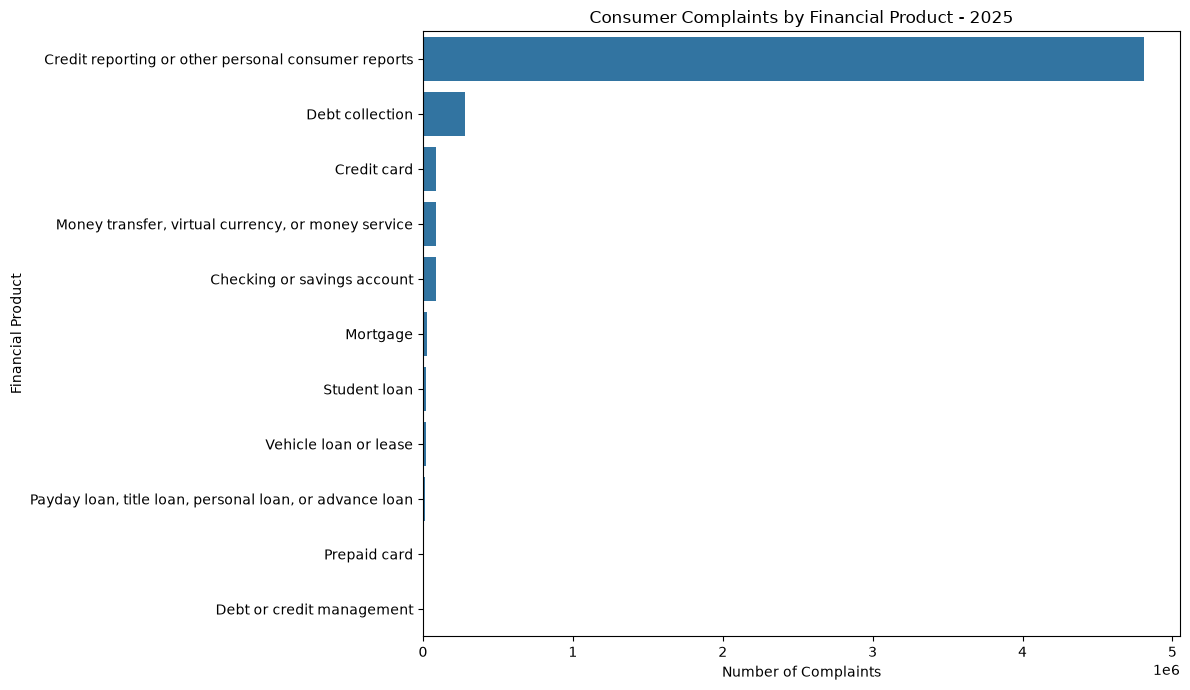

In [94]:
# Product distribution visualization

plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_distribution,
    x="Complaint Count",
    y="Product"
)

plt.title("Consumer Complaints by Financial Product - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("Financial Product")

plt.tight_layout()
plt.savefig("../visualizations/product_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

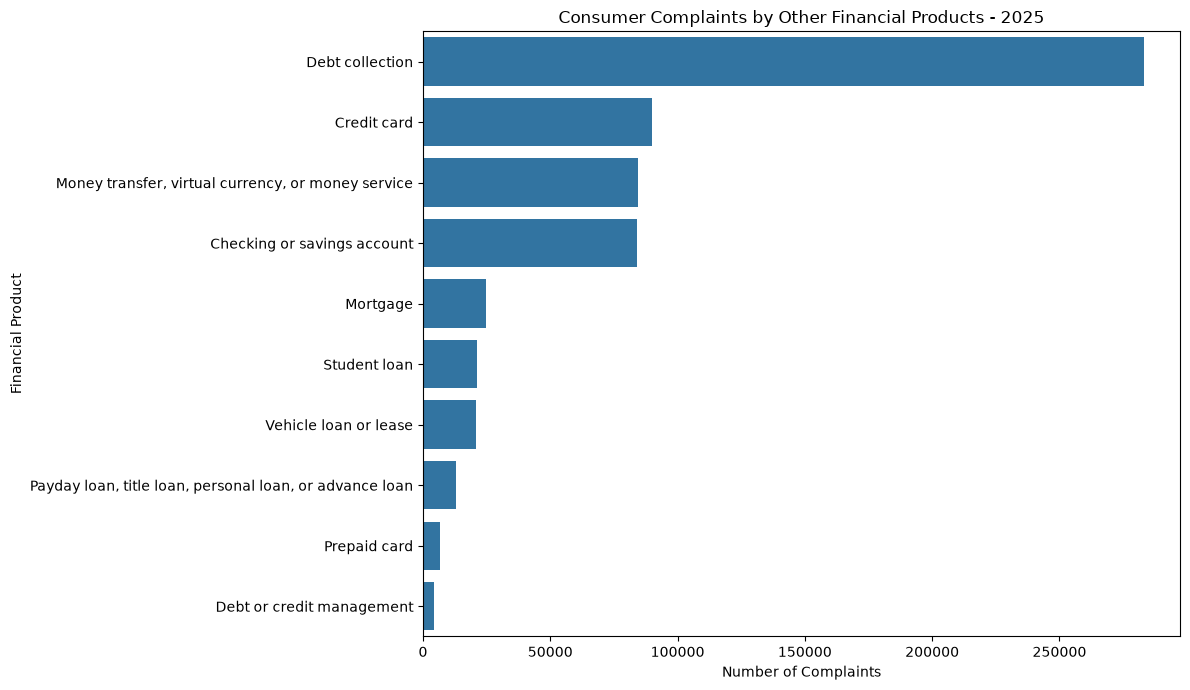

In [95]:
# Exclude credit reporting to examine smaller categories

other_products = product_distribution[
    product_distribution["Product"] !=
    "Credit reporting or other personal consumer reports"
]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=other_products,
    x="Complaint Count",
    y="Product"
)

plt.title("Consumer Complaints by Other Financial Products - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("Financial Product")

plt.tight_layout()

plt.savefig(
    "../visualizations/other_products_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [69]:
# Monthly complaint trends

monthly_trends = (
    df.groupby(df["Date received"].dt.month)
    .size()
    .reset_index(name="Complaint Count")
)

monthly_trends["Month"] = (
    monthly_trends["Date received"]
    .map({
        1: "Jan", 2: "Feb", 3: "Mar",
        4: "Apr", 5: "May", 6: "Jun",
        7: "Jul", 8: "Aug", 9: "Sep",
        10: "Oct", 11: "Nov", 12: "Dec"
    })
)

display(monthly_trends)

,Date received,Complaint Count,Month
0,1,475783,Jan
1,2,335235,Feb
2,3,396973,Mar
3,4,406099,Apr
4,5,415181,May
5,6,412160,Jun
6,7,473180,Jul
7,8,495566,Aug
8,9,503847,Sep
9,10,519780,Oct


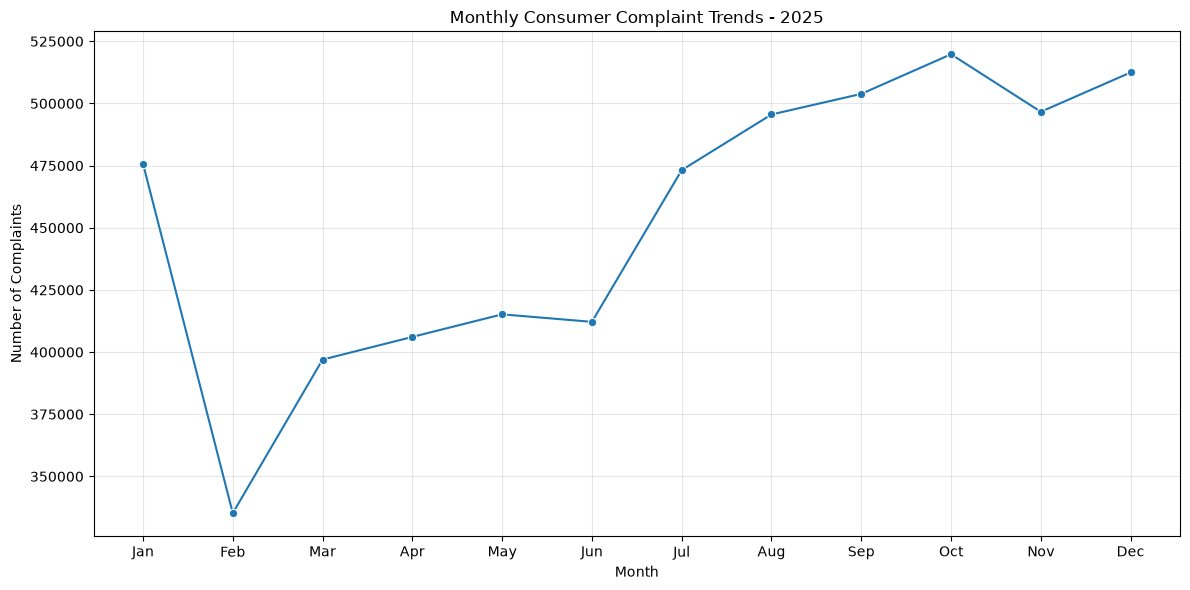

In [89]:
# Monthly complaint trend visualization

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_trends,
    x="Month",
    y="Complaint Count",
    marker="o"
)

plt.title("Monthly Consumer Complaint Trends - 2025")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../visualizations/monthly_complaint_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
# Display monthly complaint counts

display(
    monthly_trends[
        ["Month", "Complaint Count"]
    ]
)

,Month,Complaint Count
0,Jan,475783
1,Feb,335235
2,Mar,396973
3,Apr,406099
4,May,415181
5,Jun,412160
6,Jul,473180
7,Aug,495566
8,Sep,503847
9,Oct,519780


In [72]:
# Calculate month-over-month complaint growth

monthly_trends["Previous Month"] = (
    monthly_trends["Complaint Count"].shift(1)
)

monthly_trends["MoM Change"] = (
    monthly_trends["Complaint Count"]
    - monthly_trends["Previous Month"]
)

monthly_trends["MoM Growth (%)"] = (
    monthly_trends["MoM Change"]
    / monthly_trends["Previous Month"]
    * 100
).round(2)

display(monthly_trends)

,Date received,Complaint Count,Month,Previous Month,MoM Change,MoM Growth (%)
0,1,475783,Jan,NaN,NaN,NaN
1,2,335235,Feb,475783.0,-140548.0,-29.54
2,3,396973,Mar,335235.0,61738.0,18.42
3,4,406099,Apr,396973.0,9126.0,2.30
4,5,415181,May,406099.0,9082.0,2.24
5,6,412160,Jun,415181.0,-3021.0,-0.73
6,7,473180,Jul,412160.0,61020.0,14.80
7,8,495566,Aug,473180.0,22386.0,4.73
8,9,503847,Sep,495566.0,8281.0,1.67
9,10,519780,Oct,503847.0,15933.0,3.16


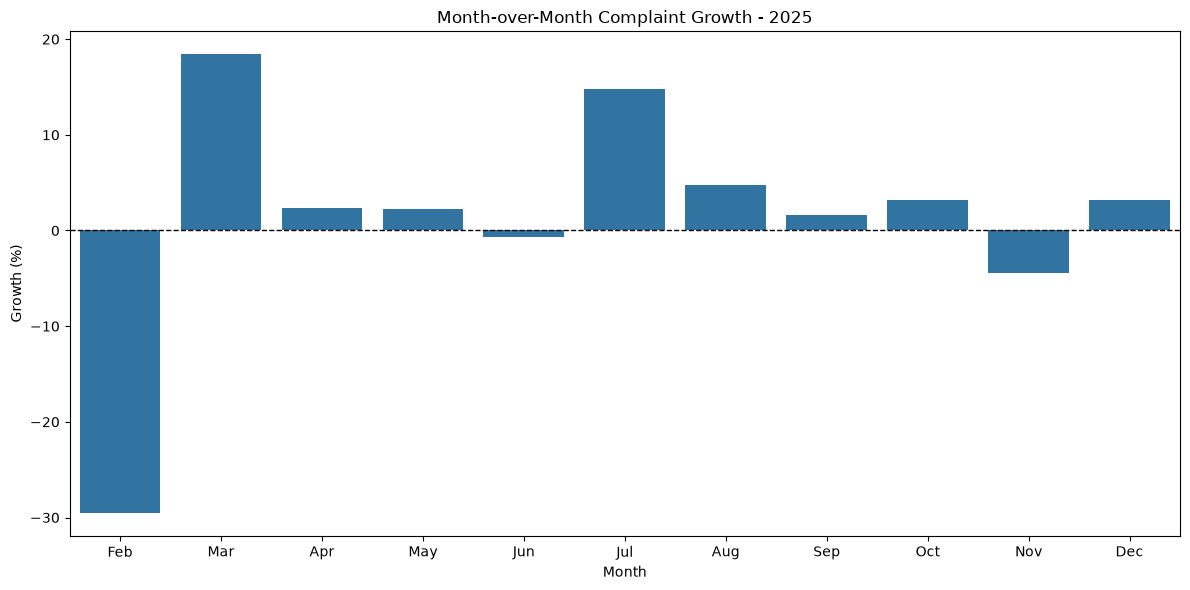

In [96]:
# Month-over-month growth visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_trends.iloc[1:],
    x="Month",
    y="MoM Growth (%)"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Month-over-Month Complaint Growth - 2025")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.tight_layout()

plt.savefig(
    "../visualizations/monthly_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
# Top 20 complaint issues

issue_distribution = (
    df["Issue"]
    .value_counts()
    .head(20)
    .reset_index()
)

issue_distribution.columns = [
    "Issue",
    "Complaint Count"
]

issue_distribution["Percentage"] = (
    issue_distribution["Complaint Count"]
    / len(df) * 100
).round(2)

display(issue_distribution)

,Issue,Complaint Count,Percentage
0,Incorrect information on your report,2834674,52.08
1,Improper use of your report,1101566,20.24
2,Problem with a company's investigation into an...,867387,15.94
3,Attempts to collect debt not owed,115681,2.13
4,Written notification about debt,64049,1.18
5,Other transaction problem,53893,0.99
6,Took or threatened to take negative or legal a...,48577,0.89
7,Managing an account,44960,0.83
8,False statements or representation,38457,0.71
9,Problem with a purchase shown on your statement,19811,0.36


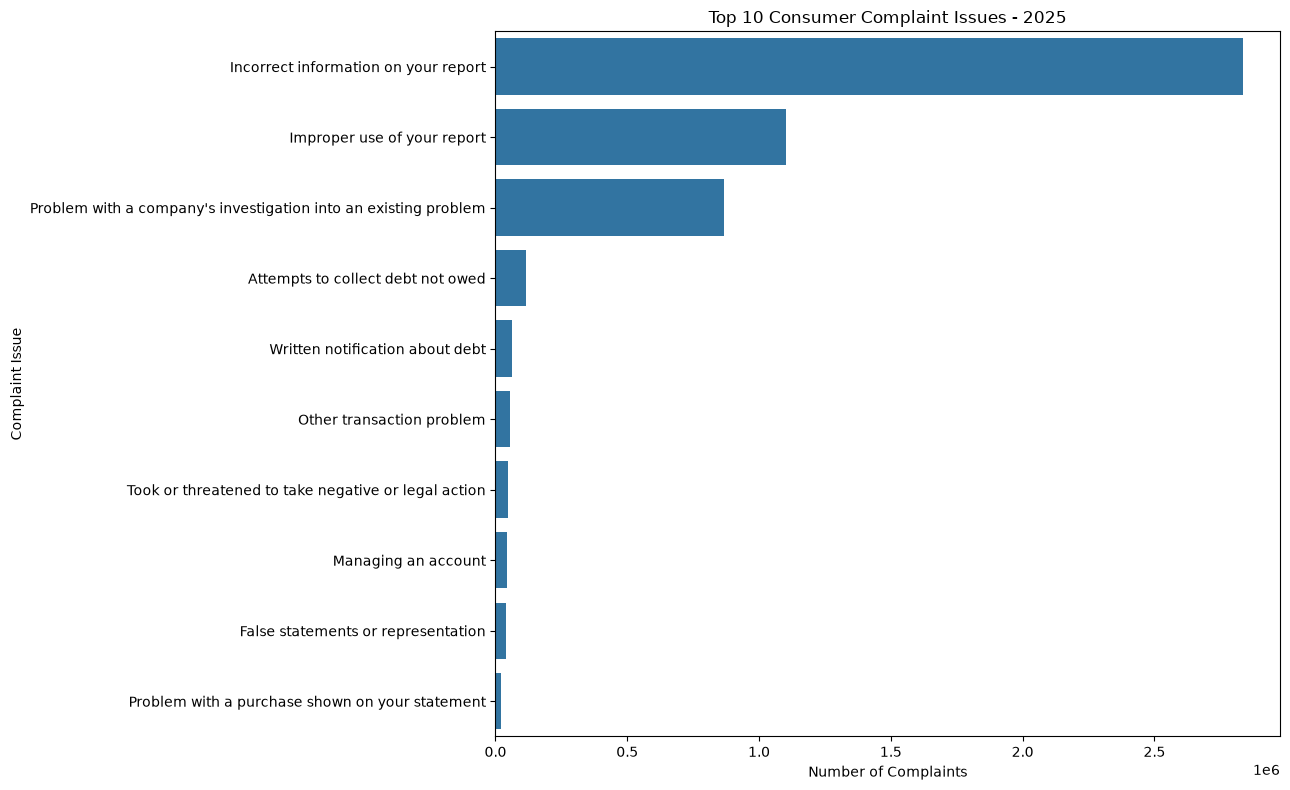

In [97]:
# Top 10 complaint issues visualization

top_10_issues = issue_distribution.head(10)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_10_issues,
    x="Complaint Count",
    y="Issue"
)

plt.title("Top 10 Consumer Complaint Issues - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Issue")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_complaint_issues.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# Top 20 companies by complaint volume

company_distribution = (
    df["Company"]
    .value_counts()
    .head(20)
    .reset_index()
)

company_distribution.columns = [
    "Company",
    "Complaint Count"
]

company_distribution["Percentage"] = (
    company_distribution["Complaint Count"]
    / len(df) * 100
).round(2)

display(company_distribution)

,Company,Complaint Count,Percentage
0,"EQUIFAX, INC.",1680537,30.88
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",1601849,29.43
2,Experian Information Solutions Inc.,1388821,25.52
3,"Block, Inc.",48091,0.88
4,CAPITAL ONE FINANCIAL CORPORATION,34102,0.63
5,"CBC Companies, Inc.",30769,0.57
6,"Early Warning Services, LLC",24509,0.45
7,JPMORGAN CHASE & CO.,24458,0.45
8,Resurgent Capital Services L.P.,23741,0.44
9,"CITIBANK, N.A.",19792,0.36


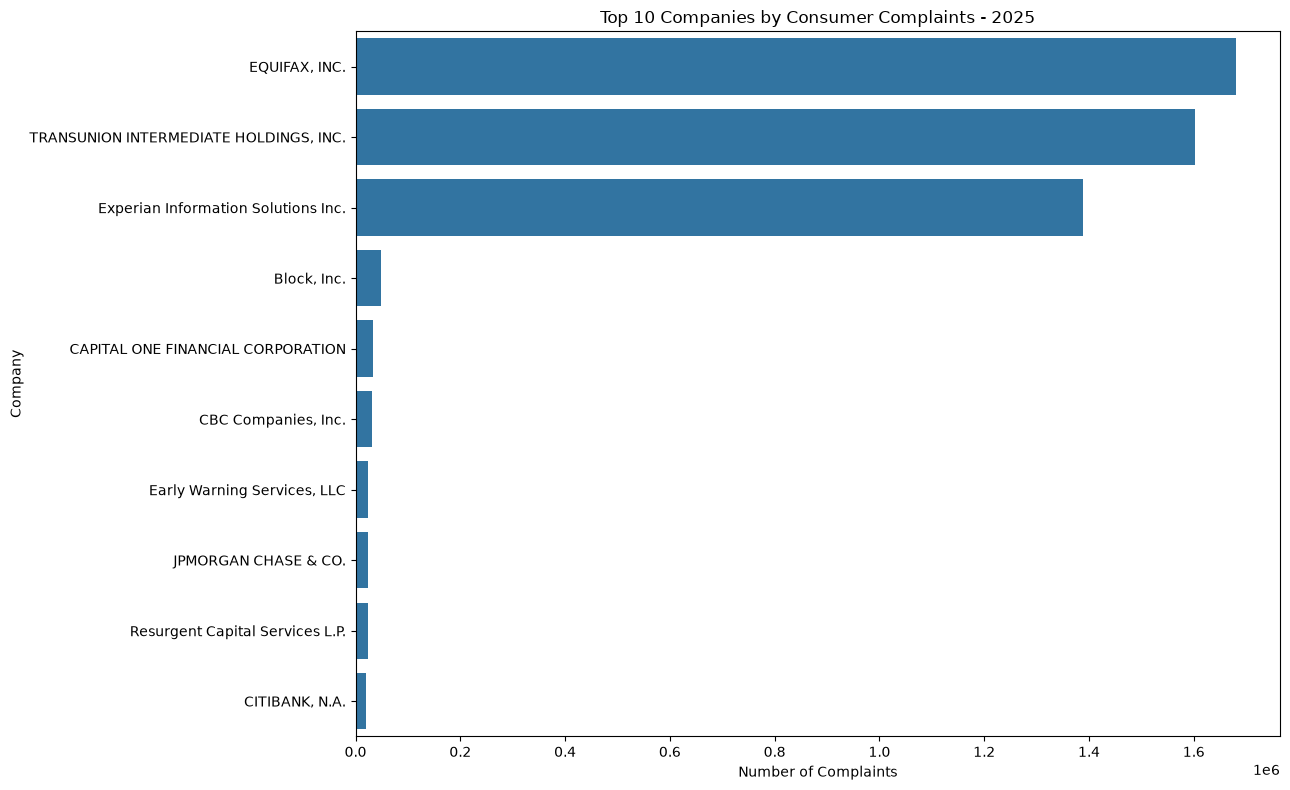

In [98]:
# Top 10 companies by complaint volume

top_10_companies = company_distribution.head(10)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_10_companies,
    x="Complaint Count",
    y="Company"
)

plt.title("Top 10 Companies by Consumer Complaints - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_companies.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

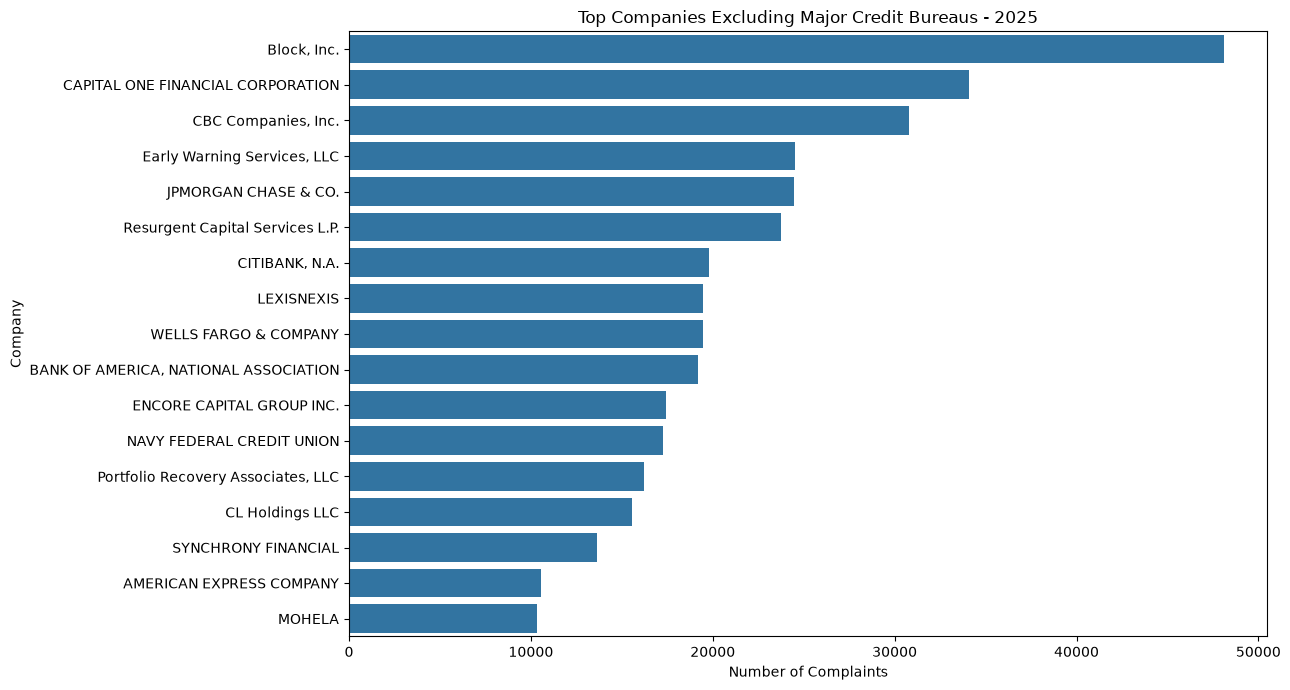

In [99]:
# Exclude the three major credit-reporting companies

credit_bureaus = [
    "EQUIFAX, INC.",
    "TRANSUNION INTERMEDIATE HOLDINGS, INC.",
    "Experian Information Solutions Inc."
]

other_companies = company_distribution[
    ~company_distribution["Company"].isin(credit_bureaus)
].copy()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=other_companies,
    x="Complaint Count",
    y="Company"
)

plt.title("Top Companies Excluding Major Credit Bureaus - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")

plt.tight_layout()

plt.savefig(
    "../visualizations/companies_excluding_top3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
# Response timeliness distribution

response_distribution = (
    df["Timely response?"]
    .value_counts()
    .reset_index()
)

response_distribution.columns = [
    "Response Timeliness",
    "Complaint Count"
]

response_distribution["Percentage"] = (
    response_distribution["Complaint Count"]
    / len(df) * 100
).round(2)

display(response_distribution)

,Response Timeliness,Complaint Count,Percentage
0,Yes,5418414,99.55
1,No,24508,0.45


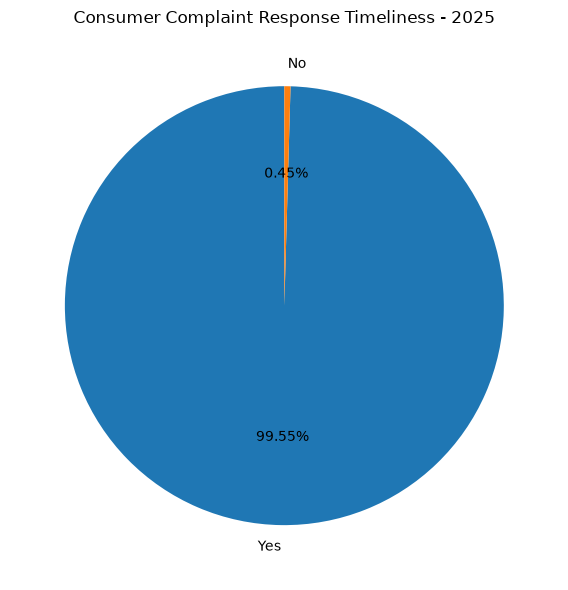

In [100]:
# Response timeliness visualization

plt.figure(figsize=(8, 6))

plt.pie(
    response_distribution["Complaint Count"],
    labels=response_distribution["Response Timeliness"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Consumer Complaint Response Timeliness - 2025")
plt.tight_layout()

plt.savefig(
    "../visualizations/response_timeliness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [81]:
# Calculate response timeliness by product

product_response = (
    df.groupby("Product")
    .agg(
        Total_Complaints=("Complaint ID", "count"),
        Untimely_Responses=(
            "Timely response?",
            lambda x: (x == "No").sum()
        )
    )
    .reset_index()
)

product_response["Untimely Rate (%)"] = (
    product_response["Untimely_Responses"]
    / product_response["Total_Complaints"]
    * 100
).round(2)

product_response = product_response.sort_values(
    "Untimely Rate (%)",
    ascending=False
)

display(product_response)

,Product,Total_Complaints,Untimely_Responses,Untimely Rate (%)
9,Student loan,21281,6460,30.36
4,Debt or credit management,4266,328,7.69
8,Prepaid card,6502,309,4.75
7,"Payday loan, title loan, personal loan, or adv...",13137,589,4.48
3,Debt collection,283193,8185,2.89
10,Vehicle loan or lease,20768,364,1.75
6,Mortgage,24697,373,1.51
5,"Money transfer, virtual currency, or money ser...",84619,1028,1.21
0,Checking or savings account,84195,609,0.72
1,Credit card,89978,345,0.38


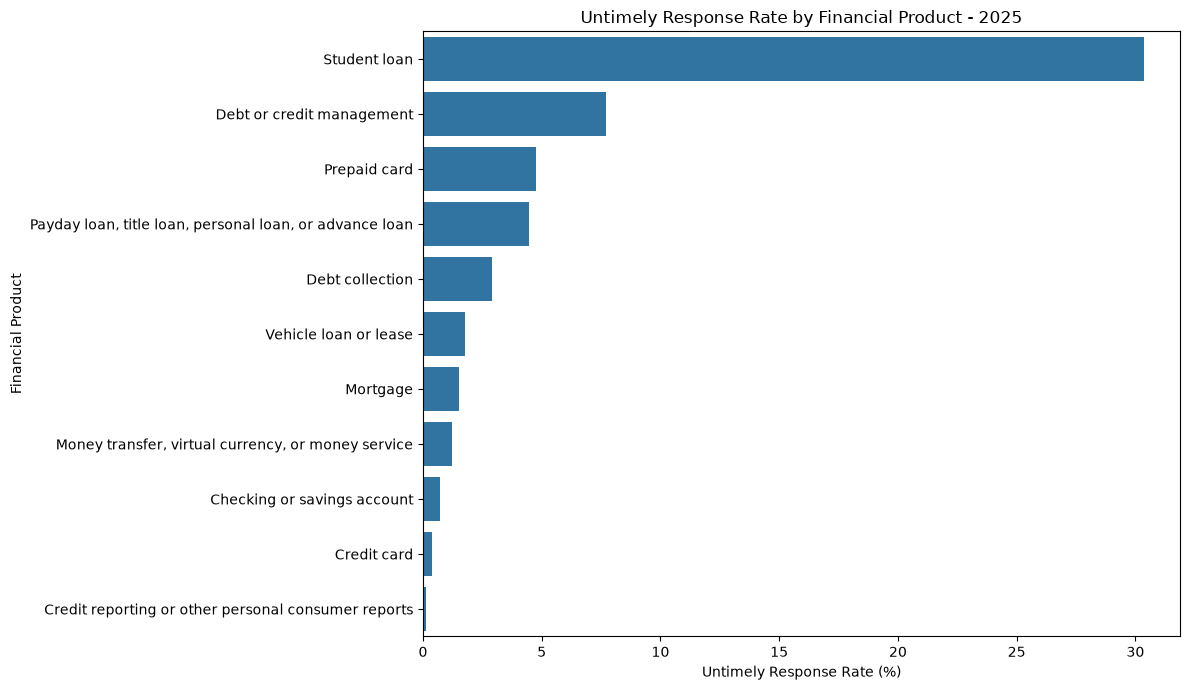

In [101]:
# Product-level untimely response rate visualization

plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_response,
    x="Untimely Rate (%)",
    y="Product"
)

plt.title("Untimely Response Rate by Financial Product - 2025")
plt.xlabel("Untimely Response Rate (%)")
plt.ylabel("Financial Product")

plt.tight_layout()

plt.savefig(
    "../visualizations/untimely_response_by_product.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [83]:
# State-level complaint distribution

state_distribution = (
    df.dropna(subset=["State"])
    ["State"]
    .value_counts()
    .reset_index()
)

state_distribution.columns = [
    "State",
    "Complaint Count"
]

state_distribution["Percentage"] = (
    state_distribution["Complaint Count"]
    / state_distribution["Complaint Count"].sum()
    * 100
).round(2)

display(state_distribution.head(20))

,State,Complaint Count,Percentage
0,FL,791231,14.56
1,TX,789895,14.53
2,CA,505426,9.30
3,GA,426934,7.86
4,NY,300036,5.52
5,IL,237648,4.37
6,NC,196066,3.61
7,PA,188543,3.47
8,NJ,166993,3.07
9,AL,144881,2.67


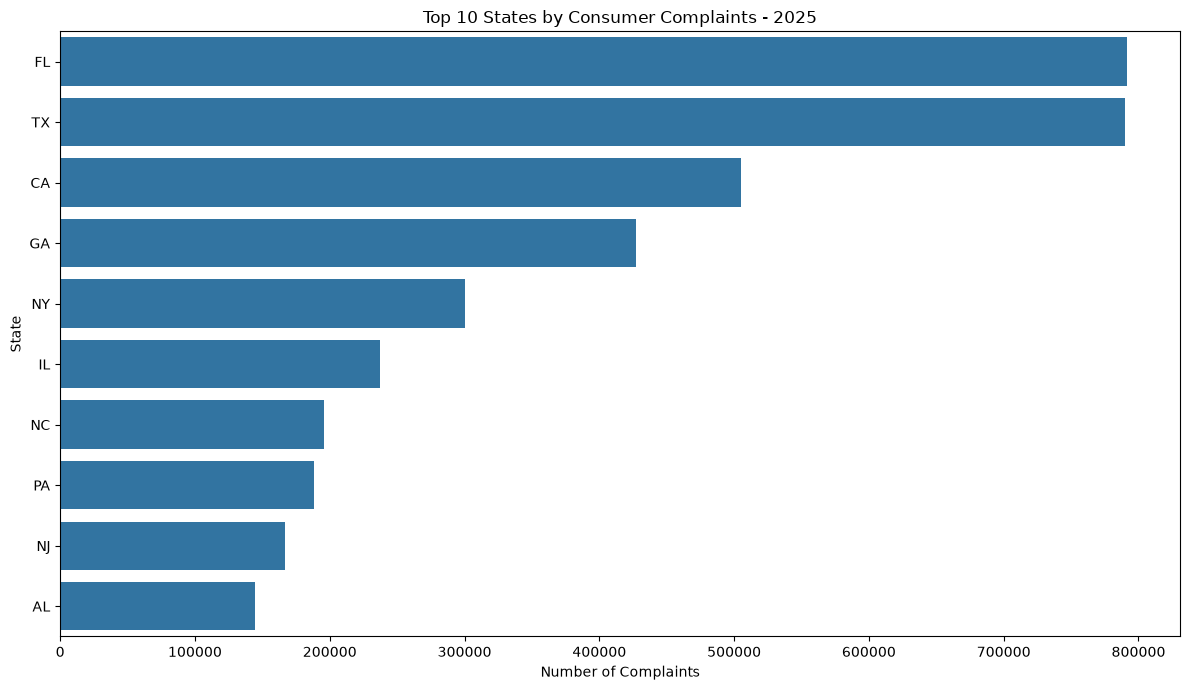

In [102]:
# Top 10 states by complaint volume

top_10_states = state_distribution.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_states,
    x="Complaint Count",
    y="State"
)

plt.title("Top 10 States by Consumer Complaints - 2025")
plt.xlabel("Number of Complaints")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_states_by_complaints.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [85]:
# Product distribution across the five leading states

top_states = ["FL", "TX", "CA", "GA", "NY"]

state_product = (
    df[df["State"].isin(top_states)]
    .groupby(["State", "Product"])
    .size()
    .reset_index(name="Complaint Count")
)

state_product["Percentage"] = (
    state_product["Complaint Count"]
    / state_product.groupby("State")["Complaint Count"].transform("sum")
    * 100
).round(2)

display(
    state_product.sort_values(
        ["State", "Complaint Count"],
        ascending=[True, False]
    )
)

,State,Product,Complaint Count,Percentage
2,CA,Credit reporting or other personal consumer re...,440276,87.11
3,CA,Debt collection,23799,4.71
1,CA,Credit card,11877,2.35
0,CA,Checking or savings account,10781,2.13
5,CA,"Money transfer, virtual currency, or money ser...",8281,1.64
6,CA,Mortgage,3008,0.60
10,CA,Vehicle loan or lease,2169,0.43
9,CA,Student loan,2056,0.41
7,CA,"Payday loan, title loan, personal loan, or adv...",1498,0.30
8,CA,Prepaid card,1301,0.26


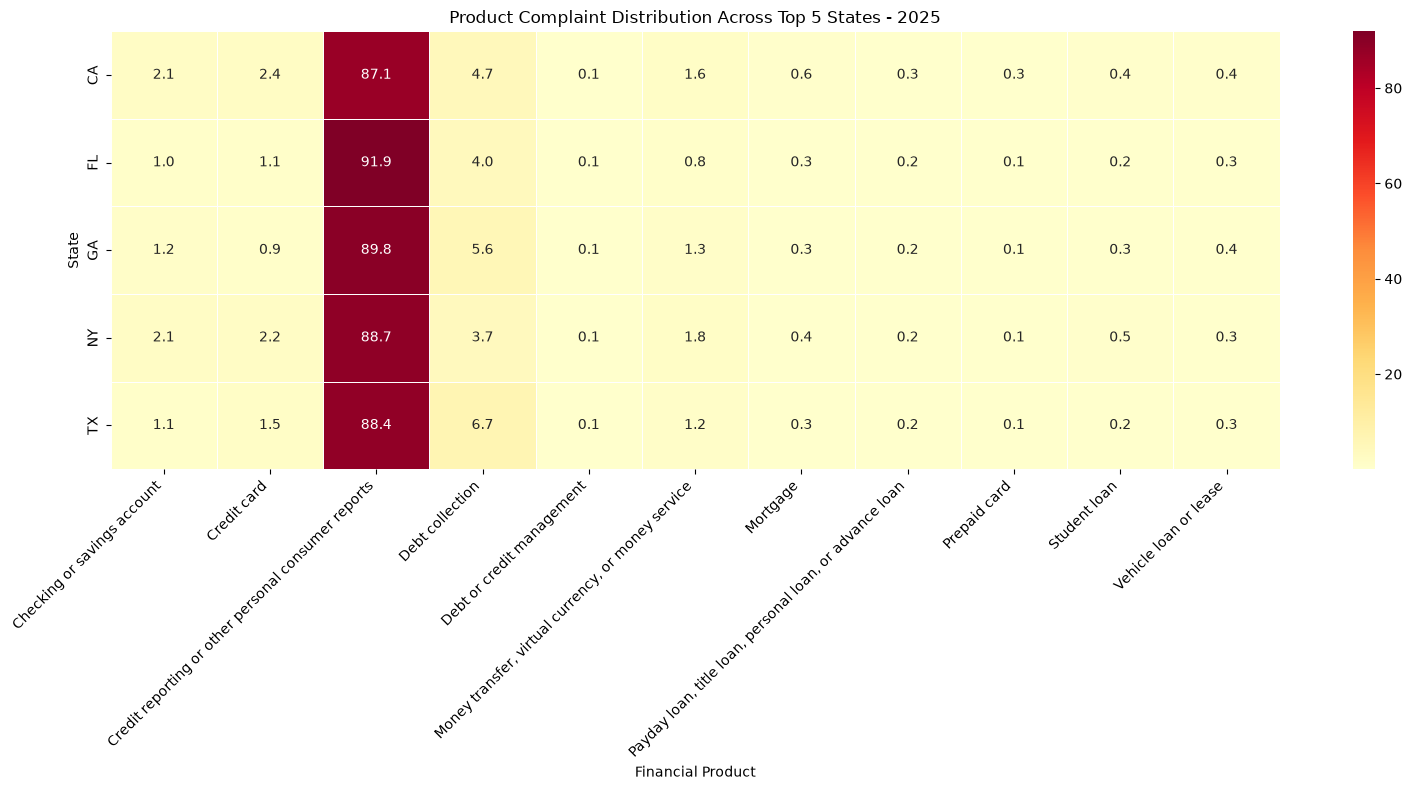

In [103]:
# Prepare data for heatmap

heatmap_data = state_product.pivot(
    index="State",
    columns="Product",
    values="Percentage"
)

plt.figure(figsize=(16, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Product Complaint Distribution Across Top 5 States - 2025")
plt.xlabel("Financial Product")
plt.ylabel("State")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()


plt.savefig(
    "../visualizations/state_product_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [104]:
import os

visualization_files = sorted(os.listdir("../visualizations"))

for file in visualization_files:
    print(file)

companies_excluding_top3.png
monthly_complaint_trends.png
monthly_growth.png
other_products_distribution.png
product_distribution.png
response_timeliness.png
state_product_heatmap.png
top_companies.png
top_complaint_issues.png
top_states_by_complaints.png
untimely_response_by_product.png


In [105]:
import os

placeholder = "../visualizations/chart_name.png"

if os.path.exists(placeholder):
    os.remove(placeholder)

files = sorted(os.listdir("../visualizations"))

print(f"Total visualizations: {len(files)}")
for file in files:
    print(file)

Total visualizations: 11
companies_excluding_top3.png
monthly_complaint_trends.png
monthly_growth.png
other_products_distribution.png
product_distribution.png
response_timeliness.png
state_product_heatmap.png
top_companies.png
top_complaint_issues.png
top_states_by_complaints.png
untimely_response_by_product.png
